In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.nonlinear_offline import OfflineFxLMS
from src.measure_ir import *

In [2]:
data = np.load('./data/poster_normal_irs.npz')

error_learning = data['error_learning']
ref_learning = data['ref_learning']

error_frozen = data['error_frozen']
ref_frozen = data['ref_frozen']

error_foam = data['error_foam']
ref_foam = data['ref_foam']

error_opt_frozen = data['error_opt_frozen']
ref_opt_frozen = data['ref_opt_frozen']

error_opt_learning = data['error_opt_learning']
ref_opt_learning = data['ref_opt_learning']

cancel_gain_opt = data['cancel_gain_opt']
weights_from_opt = data['weights_from_opt']
w_norm_from_opt = data['w_norm_from_opt']

error_nc = data['error_nc']
ref_nc = data['ref_nc']
source = data['source']

error_ir = data['error_ir']
ref_ir = data['ref_ir']
error_ir_raw = data['error_ir_raw']
ref_ir_raw = data['ref_ir_raw']

learned_weights = data['learned_weights']
w_norm_log = data['w_norm_log']
w_norm = data['w_norm']

w_ls = data['w_ls']

n_repeats = int(data['n_repeats'])
fs = int(data['fs'])
ir_len = int(data['ir_len'])
panel_to_err_cm = float(data['panel_to_err_cm'])

mu = float(data['mu'])
leak = float(data['leak'])
eps = float(data['eps'])
lag = int(data['lag'])
cancel_gain = float(data['cancel_gain'])
ref_threshold = float(data['ref_threshold'])
mavg_tau_ms = float(data['mavg_tau_ms'])
update_sign = float(data['update_sign'])

In [3]:
def trim(n_iter, ref_arr=ref_nc, error_arr=error_nc, fs=fs):
    samples = int(n_iter * 5 * fs)
    return ref_arr[:samples], error_arr[:samples]

In [4]:
fx = OfflineFxLMS(
    M=1024,
    error_ir=error_ir,
    ref_ir=ref_ir,
    fs=fs,
    nonlinear=True,
)

fx.set(
    mu=3e-3,
    leak=1e-7,
    eps=eps,
    lag=lag,
    cancel_gain=cancel_gain,
    ref_threshold=ref_threshold,
    mavg_tau_ms=mavg_tau_ms,
    update_sign=update_sign
)

Simulated ANC / No ANC: -8.75 dB


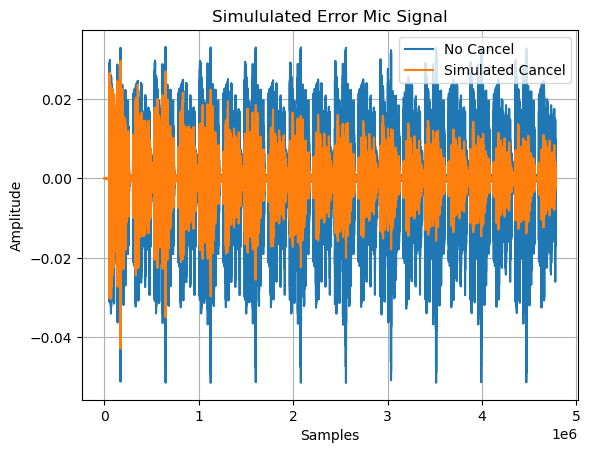

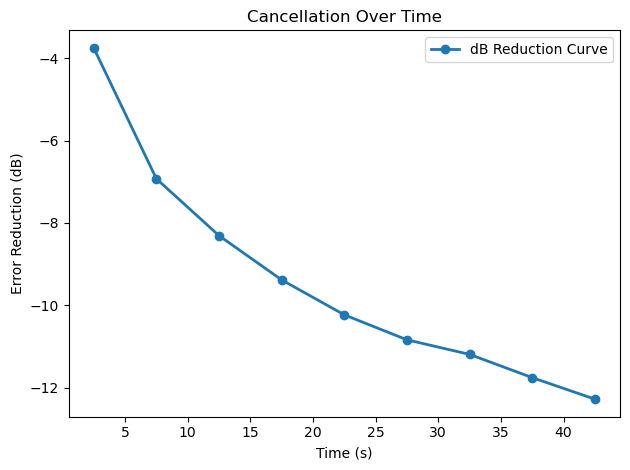

Immediate check: -8.753156 dB  |  rounded: -8.75 dB


In [28]:
fx.reset()
r_nc, e_nc = trim(10)

control, error, panel_output, weights = fx.process_array(
    r_nc, e_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    nonlinear=True
    
)

simulated_error = error  # second return value
baseline = np.asarray(e_nc, dtype=fx.dtype)  # use the exact input passed
db = fx.reduction_db(simulated_error, baseline)
print(f"Immediate check: {db:.6f} dB  |  rounded: {db:.2f} dB")

In [15]:
weights.shape

(50, 3, 1024)

Simulated ANC / No ANC: -8.81 dB


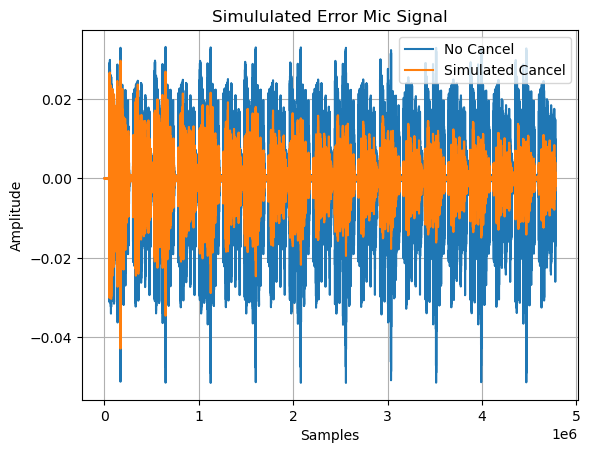

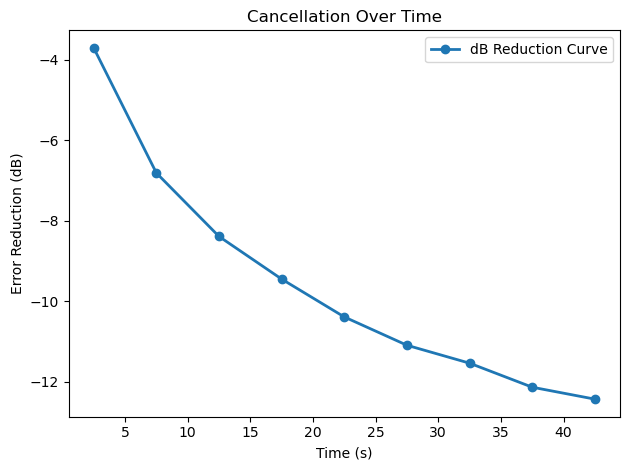

Immediate check: -8.809284 dB  |  rounded: -8.81 dB


In [26]:
fx.reset()
r_nc, e_nc = trim(10)
control_l, error_l, panel_output_l, weights_l = fx.process_array(
    r_nc, e_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    nonlinear=False
    
)

simulated_error = error_l  # second return value
baseline = np.asarray(e_nc, dtype=fx.dtype)  # use the exact input passed
db = fx.reduction_db(simulated_error, baseline)
print(f"Immediate check: {db:.6f} dB  |  rounded: {db:.2f} dB")

In [18]:
weights_l.shape

(50, 1024)

In [21]:
branch_norms = np.linalg.norm(weights, axis=2)  # (50, 3)
print(branch_norms[[0, -1]])  # columns: linear, quadratic, cubic

[[0.         0.         0.        ]
 [1.5990776  0.02791276 0.0082058 ]]


In [22]:
n = int(5 * fs)
p_lin = np.mean(np.square(error_l[-n:], dtype=np.float64))
p_nl  = np.mean(np.square(error[-n:], dtype=np.float64))
print(f"Nonlinear vs. linear residual power: {10 * np.log10(p_nl / p_lin):+.6f} dB")

Nonlinear vs. linear residual power: +0.154218 dB


In [23]:
for label, s in [("Full recording", slice(None)), ("Last 5 s", slice(-int(5 * fs), None))]:
    lin = fx.reduction_db(error_l[s], error_nc[s])
    nl  = fx.reduction_db(error[s],  error_nc[s])
    print(f"{label:15}  linear={lin:.6f}  nonlinear={nl:.6f}  Δ={nl-lin:+.6f} dB")

Full recording   linear=-7.003627  nonlinear=-7.010169  Δ=-0.006542 dB
Last 5 s         linear=-10.166933  nonlinear=-10.012714  Δ=+0.154219 dB


Normal mavg condition

Simulated ANC / No ANC: -8.18 dB


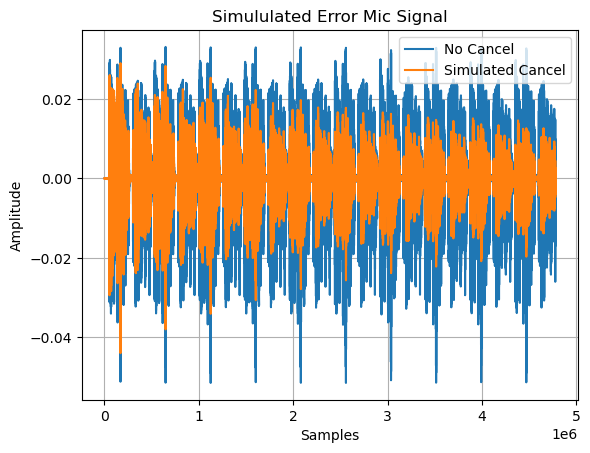

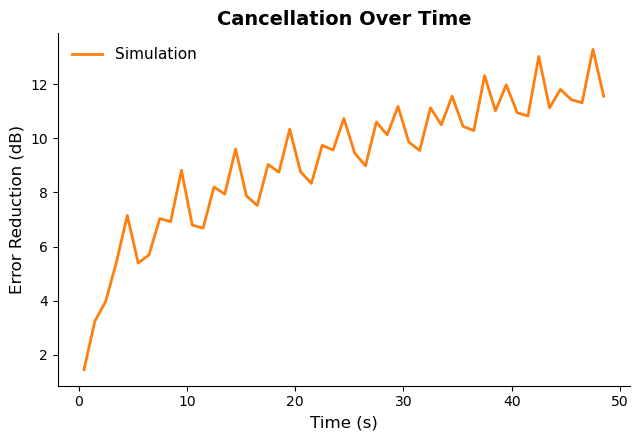

In [6]:
fx.reset()
control_n, error_n, panel_output_n, weights_n = fx.process_array(
    ref_nc, error_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    mu=5e-3,
    leak=1e-7,
    nonlinear=False
    
)

cleaned_ref < .006

Simulated ANC / No ANC: -8.18 dB


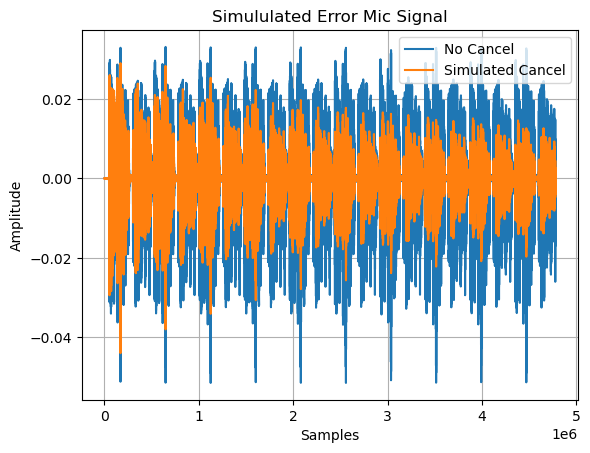

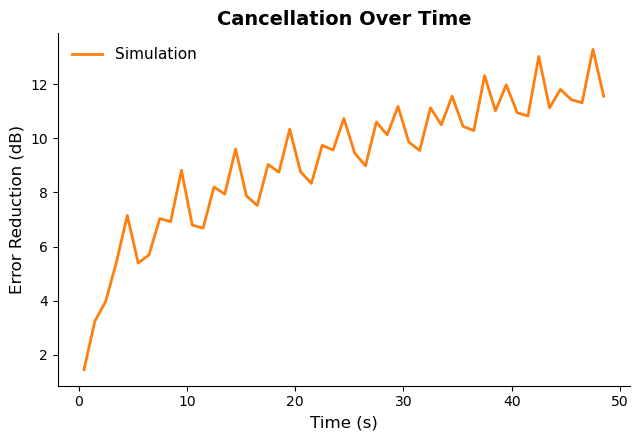

In [7]:
fx.reset()
control_l, error_l, panel_output_l, weights_l = fx.process_array(
    ref_nc, error_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    mu=5e-3,
    leak=1e-7,
    nonlinear=False
    
)

In [8]:
def plot_loss_curve(
        error_nc,
        error_1,
        error_2,
        label_1="Simulation 1",
        label_2="Simulation 2",
        window_sec=1.0,
        hop_sec=None,
        online=None,
        save_path=None,
    ):
        """Plot error reduction over time. Positive dB means less error."""
        if hop_sec is None:
            hop_sec = window_sec

        win = int(window_sec * fs)
        hop = int(hop_sec * fs)
        if win < 1 or hop < 1:
            raise ValueError("Window and hop must each span at least one sample.")

        def reduction_over_time(cancelled):
            n = min(len(cancelled), len(error_nc))
            starts = range(0, n - win + 1, hop)
            times = (np.asarray(starts) + win / 2) / fs
            reductions = [
                -fx.reduction_db(
                    cancelled[start:start + win],
                    error_nc[start:start + win],
                )
                for start in starts
            ]
            return times, np.asarray(reductions)

        fig, ax = plt.subplots(figsize=(6.5, 4.5))

        if online is not None:
            times, reduction = reduction_over_time(online)
            ax.plot(times, reduction, linewidth=2, label="Physical Space", color="C0")

        times_1, reduction_1 = reduction_over_time(error_1)
        ax.plot(times_1, reduction_1, linewidth=2, label=label_1, color="C1")

        times_2, reduction_2 = reduction_over_time(error_2)
        ax.plot(times_2, reduction_2, linewidth=2, label=label_2, color="C2")

        ax.set_xlabel("Time (s)", fontsize=12)
        ax.set_ylabel("Error Reduction (dB)", fontsize=12)
        ax.set_title("Cancellation Over Time", fontsize=14, fontweight="bold")
        ax.tick_params(labelsize=10)
        ax.legend(fontsize=11, frameon=False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        fig.tight_layout()
        if save_path is not None:
            fig.savefig(save_path, bbox_inches="tight")

        plt.show()

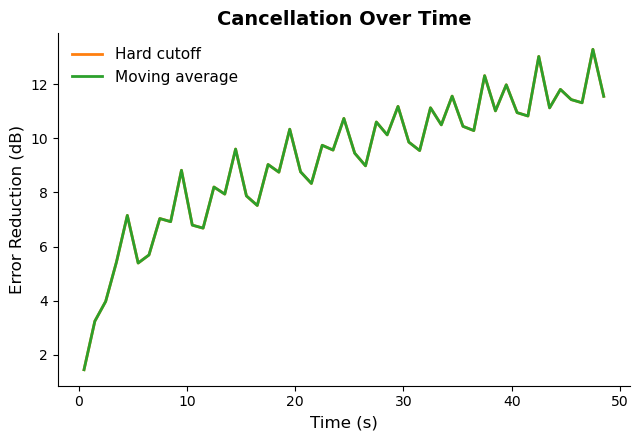

In [9]:
plot_loss_curve(
    error_nc=error_nc,
    error_1=error_l,
    error_2=error_n,
    label_1="Hard cutoff",
    label_2="Moving average",
    window_sec=1.0,
    hop_sec=None,
    online=None,
    save_path=None,
)

cleaned_ref < .01

Simulated ANC / No ANC: -7.27 dB


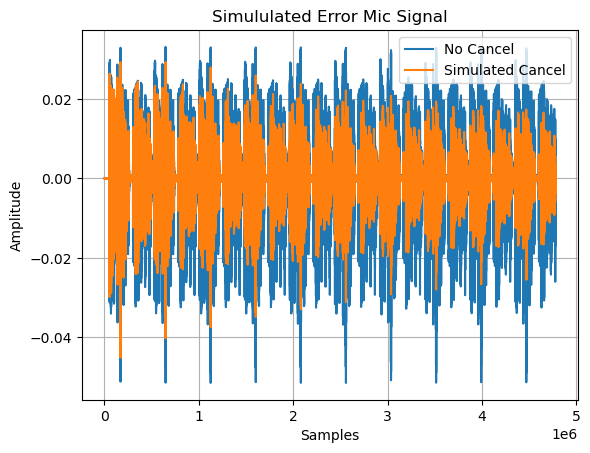

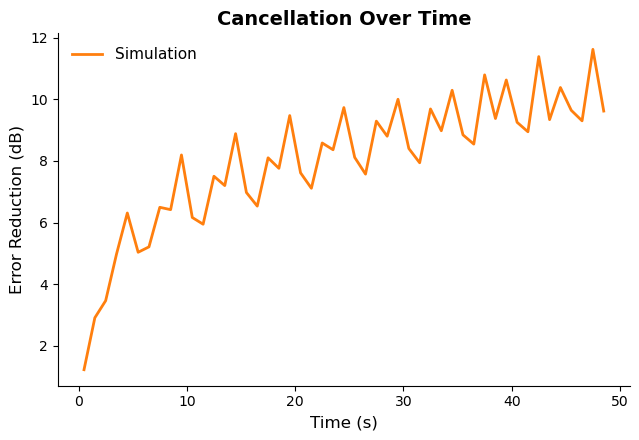

In [5]:
fx.reset()
control_l, error_l, panel_output_l, weights_l = fx.process_array(
    ref_nc, error_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    mu=5e-3,
    leak=1e-7,
    nonlinear=False
    
)

cleaned_ref < 0.001

Simulated ANC / No ANC: -8.18 dB


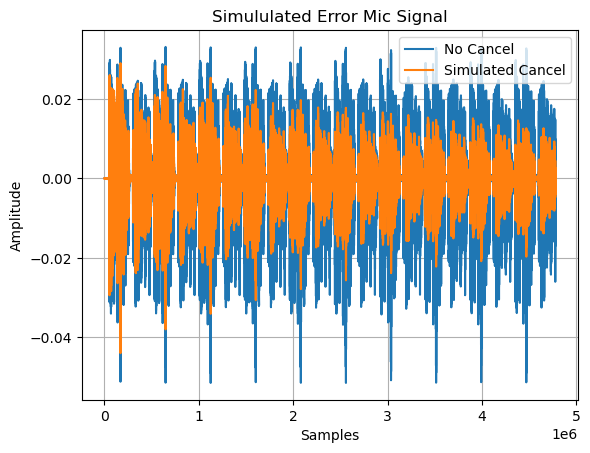

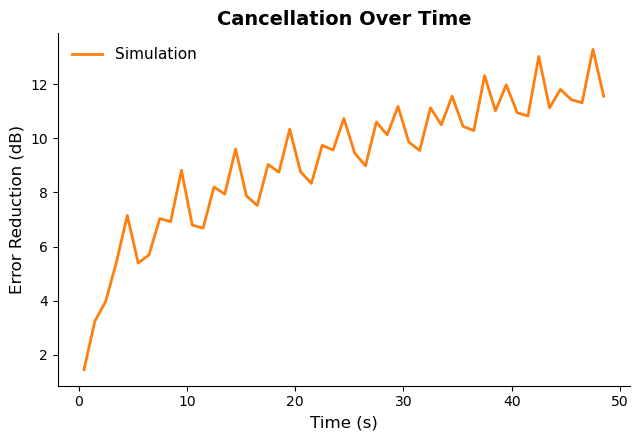

In [5]:
fx.reset()
control_l, error_l, panel_output_l, weights_l = fx.process_array(
    ref_nc, error_nc,
    adapt=True,
    save_weight_every_s=0.5,
    plot=True,
    mu=5e-3,
    leak=1e-7,
    nonlinear=False
    
)